In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://huggingface.co/datasets/haoxianc/aliiihussain_social-media-viral-content-and-engagement-metrics/resolve/main/social_media_viral_content_dataset.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,post_id,platform,content_type,topic,language,region,post_datetime,hashtags,views,likes,comments,shares,engagement_rate,sentiment_score,is_viral
0,SM_100000,Instagram,text,Sports,ur,UK,2024-12-10 00:00:00,#tech #funny #music,2319102,122058,15800,861,0.0598,0.464,1
1,SM_100001,Instagram,carousel,Sports,ur,Brazil,2024-10-13 00:00:00,#news #fyp #funny #ai #trending,2538464,110368,11289,54887,0.0695,-0.800,1
2,SM_100002,YouTube Shorts,video,Technology,ur,UK,2024-05-03 00:00:00,#ai #news,1051176,87598,47196,44132,0.1702,0.416,0
3,SM_100003,X,text,Politics,ur,US,2024-08-04 00:00:00,#ai #funny,5271440,329465,774,59736,0.0740,0.877,1
4,SM_100004,YouTube Shorts,text,Education,es,US,2024-03-28 00:00:00,#news #ai #viral #funny #fyp,3186256,199141,5316,83105,0.0903,0.223,1


In [4]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 2000
Number of Columns: 15


In [5]:
print(df.columns.tolist())

['post_id', 'platform', 'content_type', 'topic', 'language', 'region', 'post_datetime', 'hashtags', 'views', 'likes', 'comments', 'shares', 'engagement_rate', 'sentiment_score', 'is_viral']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   post_id          2000 non-null   object 
 1   platform         2000 non-null   object 
 2   content_type     2000 non-null   object 
 3   topic            2000 non-null   object 
 4   language         2000 non-null   object 
 5   region           2000 non-null   object 
 6   post_datetime    2000 non-null   object 
 7   hashtags         2000 non-null   object 
 8   views            2000 non-null   int64  
 9   likes            2000 non-null   int64  
 10  comments         2000 non-null   int64  
 11  shares           2000 non-null   int64  
 12  engagement_rate  2000 non-null   float64
 13  sentiment_score  2000 non-null   float64
 14  is_viral         2000 non-null   int64  
dtypes: float64(2), int64(5), object(8)
memory usage: 234.5+ KB


In [7]:
df.describe()

,views,likes,comments,shares,engagement_rate,sentiment_score,is_viral
count,2.000000e+03,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,4.284860e+06,245329.244000,24786.929000,49936.981500,0.157852,-0.000566,0.699000
std,3.246193e+06,145032.423582,14433.288364,29012.818697,0.535457,0.574911,0.458807
min,4.380000e+03,292.000000,14.000000,127.000000,0.035700,-1.000000,0.000000
25%,1.652742e+06,118903.750000,12337.750000,25698.750000,0.057975,-0.507000,0.000000
50%,3.469408e+06,239831.000000,24519.500000,50212.000000,0.084500,0.001000,1.000000
75%,6.348078e+06,372323.500000,37116.250000,75433.000000,0.142525,0.495250,1.000000
max,1.437179e+07,499983.000000,49989.000000,99977.000000,12.573200,0.999000,1.000000


In [8]:
print(df.shape)
print(df.columns.tolist())
print(df.isnull().sum())

(2000, 15)
['post_id', 'platform', 'content_type', 'topic', 'language', 'region', 'post_datetime', 'hashtags', 'views', 'likes', 'comments', 'shares', 'engagement_rate', 'sentiment_score', 'is_viral']
post_id            0
platform           0
content_type       0
topic              0
language           0
region             0
post_datetime      0
hashtags           0
views              0
likes              0
comments           0
shares             0
engagement_rate    0
sentiment_score    0
is_viral           0
dtype: int64


In [9]:
# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Check duplicate post IDs
print("Duplicate Post IDs:", df['post_id'].duplicated().sum())

Duplicate Rows: 0
Duplicate Post IDs: 0


In [10]:
print(df.dtypes)

post_id             object
platform            object
content_type        object
topic               object
language            object
region              object
post_datetime       object
hashtags            object
views                int64
likes                int64
comments             int64
shares               int64
engagement_rate    float64
sentiment_score    float64
is_viral             int64
dtype: object


In [11]:
numeric_columns = [
    'views', 'likes', 'comments', 'shares',
    'engagement_rate', 'sentiment_score'
]

print(df[numeric_columns].describe())

              views          likes      comments        shares  \
count  2.000000e+03    2000.000000   2000.000000   2000.000000   
mean   4.284860e+06  245329.244000  24786.929000  49936.981500   
std    3.246193e+06  145032.423582  14433.288364  29012.818697   
min    4.380000e+03     292.000000     14.000000    127.000000   
25%    1.652742e+06  118903.750000  12337.750000  25698.750000   
50%    3.469408e+06  239831.000000  24519.500000  50212.000000   
75%    6.348078e+06  372323.500000  37116.250000  75433.000000   
max    1.437179e+07  499983.000000  49989.000000  99977.000000   

       engagement_rate  sentiment_score  
count      2000.000000      2000.000000  
mean          0.157852        -0.000566  
std           0.535457         0.574911  
min           0.035700        -1.000000  
25%           0.057975        -0.507000  
50%           0.084500         0.001000  
75%           0.142525         0.495250  
max          12.573200         0.999000  


In [12]:
for col in numeric_columns:
    print(col, "Negative values:", (df[col] < 0).sum())

views Negative values: 0
likes Negative values: 0
comments Negative values: 0
shares Negative values: 0
engagement_rate Negative values: 0
sentiment_score Negative values: 999


In [13]:
print("Zero View Posts:", (df['views'] == 0).sum())

Zero View Posts: 0


In [14]:
print(df['is_viral'].value_counts())

is_viral
1    1398
0     602
Name: count, dtype: int64


In [15]:
df['post_datetime'] = pd.to_datetime(
    df['post_datetime'],
    errors='coerce'
)

print(df['post_datetime'].dtype)

datetime64[ns]


In [16]:
cleaning_report = pd.DataFrame({
    'Check': [
        'Total Records',
        'Total Columns',
        'Missing Values',
        'Duplicate Rows',
        'Duplicate Post IDs',
        'Zero View Posts',
        'Invalid Dates'
    ],
    'Count': [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df['post_id'].duplicated().sum(),
        (df['views'] == 0).sum(),
        df['post_datetime'].isnull().sum()
    ]
})

display(cleaning_report)

,Check,Count
0,Total Records,2000
1,Total Columns,15
2,Missing Values,0
3,Duplicate Rows,0
4,Duplicate Post IDs,0
5,Zero View Posts,0
6,Invalid Dates,0


In [17]:
df_clean = df.copy()

# Standardize text columns
text_columns = [
    'platform', 'content_type', 'topic',
    'language', 'region'
]

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

# Convert date column
df_clean['post_datetime'] = pd.to_datetime(
    df_clean['post_datetime']
)

print("Working dataset created successfully!")
print(df_clean.shape)

Working dataset created successfully!
(2000, 15)


In [18]:
numeric_columns = [
    'views', 'likes', 'comments',
    'shares', 'engagement_rate', 'sentiment_score'
]

display(df_clean[numeric_columns].describe())

,views,likes,comments,shares,engagement_rate,sentiment_score
count,2.000000e+03,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,4.284860e+06,245329.244000,24786.929000,49936.981500,0.157852,-0.000566
std,3.246193e+06,145032.423582,14433.288364,29012.818697,0.535457,0.574911
min,4.380000e+03,292.000000,14.000000,127.000000,0.035700,-1.000000
25%,1.652742e+06,118903.750000,12337.750000,25698.750000,0.057975,-0.507000
50%,3.469408e+06,239831.000000,24519.500000,50212.000000,0.084500,0.001000
75%,6.348078e+06,372323.500000,37116.250000,75433.000000,0.142525,0.495250
max,1.437179e+07,499983.000000,49989.000000,99977.000000,12.573200,0.999000


In [19]:
for col in numeric_columns:
    print(f"{col}: {(df_clean[col] < 0).sum()} negative values")

views: 0 negative values
likes: 0 negative values
comments: 0 negative values
shares: 0 negative values
engagement_rate: 0 negative values
sentiment_score: 999 negative values


In [20]:
df_clean['total_engagement'] = (
    df_clean['likes'] +
    df_clean['comments'] +
    df_clean['shares']
)

df_clean['calculated_engagement_rate'] = (
    df_clean['total_engagement'] /
    df_clean['views']
) * 100

display(df_clean[[
    'post_id',
    'views',
    'likes',
    'comments',
    'shares',
    'engagement_rate',
    'calculated_engagement_rate'
]].head(10))

,post_id,views,likes,comments,shares,engagement_rate,calculated_engagement_rate
0,SM_100000,2319102,122058,15800,861,0.0598,5.981583
1,SM_100001,2538464,110368,11289,54887,0.0695,6.954757
2,SM_100002,1051176,87598,47196,44132,0.1702,17.021507
3,SM_100003,5271440,329465,774,59736,0.0740,7.397884
4,SM_100004,3186256,199141,5316,83105,0.0903,9.025075
5,SM_100005,6513472,465248,27485,25659,0.0796,7.958766
6,SM_100006,65481,2847,194,84655,1.3393,133.925872
7,SM_100007,2961423,329047,31556,11395,0.1256,12.561461
8,SM_100008,3916736,489592,14507,87314,0.1510,15.099639
9,SM_100009,3116477,239729,8438,43002,0.0934,9.342889


is_viral
1    1398
0     602
Name: count, dtype: int64


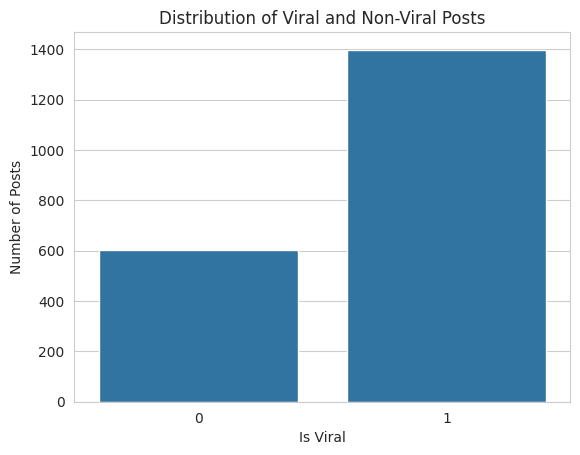

In [21]:
print(df_clean['is_viral'].value_counts())

sns.countplot(data=df_clean, x='is_viral')

plt.title('Distribution of Viral and Non-Viral Posts')
plt.xlabel('Is Viral')
plt.ylabel('Number of Posts')
plt.show()

In [22]:
df_clean['dataset_rate_percent'] = df_clean['engagement_rate'] * 100

df_clean['rate_difference'] = abs(
    df_clean['dataset_rate_percent'] -
    df_clean['calculated_engagement_rate']
)

verification = df_clean[[
    'post_id',
    'views',
    'likes',
    'comments',
    'shares',
    'dataset_rate_percent',
    'calculated_engagement_rate',
    'rate_difference'
]].head(10)

display(verification.round(4))

print(
    "Average difference:",
    df_clean['rate_difference'].mean()
)

print(
    "Maximum difference:",
    df_clean['rate_difference'].max()
)

,post_id,views,likes,comments,shares,dataset_rate_percent,calculated_engagement_rate,rate_difference
0,SM_100000,2319102,122058,15800,861,5.98,5.9816,0.0016
1,SM_100001,2538464,110368,11289,54887,6.95,6.9548,0.0048
2,SM_100002,1051176,87598,47196,44132,17.02,17.0215,0.0015
3,SM_100003,5271440,329465,774,59736,7.40,7.3979,0.0021
4,SM_100004,3186256,199141,5316,83105,9.03,9.0251,0.0049
5,SM_100005,6513472,465248,27485,25659,7.96,7.9588,0.0012
6,SM_100006,65481,2847,194,84655,133.93,133.9259,0.0041
7,SM_100007,2961423,329047,31556,11395,12.56,12.5615,0.0015
8,SM_100008,3916736,489592,14507,87314,15.10,15.0996,0.0004
9,SM_100009,3116477,239729,8438,43002,9.34,9.3429,0.0029


Average difference: 0.0025048572811427615
Maximum difference: 0.004998598634117002


In [23]:
print("Engagement rate above 100%:",
      (df_clean['calculated_engagement_rate'] > 100).sum())

print("Engagement rate below 0%:",
      (df_clean['calculated_engagement_rate'] < 0).sum())

display(
    df_clean.nlargest(
        10, 'calculated_engagement_rate'
    )[[
        'post_id',
        'views',
        'likes',
        'comments',
        'shares',
        'calculated_engagement_rate'
    ]]
)

Engagement rate above 100%: 24
Engagement rate below 0%: 0


,post_id,views,likes,comments,shares,calculated_engagement_rate
1170,SM_101170,10500,420,37427,94172,1257.323810
941,SM_100941,4380,292,36418,12817,1130.753425
1779,SM_101779,5516,394,32541,24597,1043.002175
1489,SM_101489,8294,754,17148,55935,890.245961
1654,SM_101654,30800,1232,38264,96613,441.912338
1404,SM_101404,19644,3274,35403,35930,379.795357
764,SM_100764,18856,2357,27369,24973,290.088036
1286,SM_101286,40810,5830,13926,98431,289.603038
565,SM_100565,49994,3571,41801,95805,282.387887
1218,SM_101218,43848,1566,30776,83887,265.072523


In [24]:
interaction_columns = ['likes', 'comments', 'shares']

for col in interaction_columns:
    count = (df_clean[col] > df_clean['views']).sum()
    print(f"{col} greater than views: {count}")

df_clean['total_engagement'] = (
    df_clean['likes'] +
    df_clean['comments'] +
    df_clean['shares']
)

df_clean['interaction_exceeds_views'] = (
    df_clean['total_engagement'] > df_clean['views']
)

print(
    "\nPosts where total engagement exceeds views:",
    df_clean['interaction_exceeds_views'].sum()
)

display(
    df_clean[df_clean['interaction_exceeds_views']][[
        'post_id', 'views', 'likes',
        'comments', 'shares',
        'calculated_engagement_rate'
    ]].head(10)
)

likes greater than views: 0
comments greater than views: 10
shares greater than views: 14

Posts where total engagement exceeds views: 24


,post_id,views,likes,comments,shares,calculated_engagement_rate
6,SM_100006,65481,2847,194,84655,133.925872
73,SM_100073,24684,4114,11098,18071,134.836331
92,SM_100092,119448,17064,47898,59639,104.314011
184,SM_100184,18592,1162,29931,6230,200.747633
459,SM_100459,86961,12423,45804,73380,151.340256
565,SM_100565,49994,3571,41801,95805,282.387887
764,SM_100764,18856,2357,27369,24973,290.088036
895,SM_100895,59332,4238,35197,91177,220.137531
922,SM_100922,122591,17513,48119,59501,102.073562
941,SM_100941,4380,292,36418,12817,1130.753425


In [25]:
Q1 = df_clean['views'].quantile(0.25)
Q3 = df_clean['views'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df_clean['view_outlier'] = (
    (df_clean['views'] < lower_limit) |
    (df_clean['views'] > upper_limit)
)

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

print(
    "Number of view outliers:",
    df_clean['view_outlier'].sum()
)

display(
    df_clean[df_clean['view_outlier']][[
        'post_id', 'views', 'likes',
        'comments', 'shares',
        'calculated_engagement_rate'
    ]].head(10)
)

Lower limit: -5390262.0
Upper limit: 13391082.0
Number of view outliers: 7


,post_id,views,likes,comments,shares,calculated_engagement_rate
582,SM_100582,14371791,495579,45956,22670,3.925781
917,SM_100917,14087823,485787,21230,3607,3.624577
1026,SM_101026,13878066,478554,25571,73194,4.159938
1678,SM_101678,13847123,477487,25633,31363,3.859885
1789,SM_101789,13973960,499070,11100,57573,4.062864
1870,SM_101870,13396266,496158,18613,67263,4.344748
1995,SM_101995,14112183,486627,9430,91550,4.163828


In [26]:
# Convert post_datetime into datetime format
df_clean['post_datetime'] = pd.to_datetime(
    df_clean['post_datetime']
)

# Extract day and hour
df_clean['posting_day'] = df_clean['post_datetime'].dt.day_name()
df_clean['posting_hour'] = df_clean['post_datetime'].dt.hour

# Set the correct weekday order
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

print("Date and time features created successfully!")

display(
    df_clean[[
        'post_id',
        'post_datetime',
        'posting_day',
        'posting_hour'
    ]].head(10)
)

Date and time features created successfully!


,post_id,post_datetime,posting_day,posting_hour
0,SM_100000,2024-12-10,Tuesday,0
1,SM_100001,2024-10-13,Sunday,0
2,SM_100002,2024-05-03,Friday,0
3,SM_100003,2024-08-04,Sunday,0
4,SM_100004,2024-03-28,Thursday,0
5,SM_100005,2024-11-01,Friday,0
6,SM_100006,2024-06-09,Sunday,0
7,SM_100007,2024-07-26,Friday,0
8,SM_100008,2024-03-03,Sunday,0
9,SM_100009,2024-10-05,Saturday,0


In [27]:
content_analysis = df_clean.groupby('content_type').agg(
    total_posts=('post_id', 'count'),
    average_engagement=('calculated_engagement_rate', 'mean'),
    median_engagement=('calculated_engagement_rate', 'median'),
    average_views=('views', 'mean')
).sort_values(
    by='median_engagement',
    ascending=False
)

display(content_analysis.round(2))

,total_posts,average_engagement,median_engagement,average_views
content_type,,,,
text,488,18.39,8.80,4200584.64
image,512,16.10,8.80,4162955.02
video,472,14.92,8.20,4532329.75
carousel,528,13.86,8.12,4259737.17


In [28]:
day_analysis = df_clean.groupby('posting_day').agg(
    total_posts=('post_id', 'count'),
    average_engagement=('calculated_engagement_rate', 'mean'),
    median_engagement=('calculated_engagement_rate', 'median'),
    average_views=('views', 'mean')
).reindex(day_order)

display(day_analysis.round(2))

,total_posts,average_engagement,median_engagement,average_views
posting_day,,,,
Monday,280,21.61,8.29,4330179.73
Tuesday,288,18.64,8.66,4410744.74
Wednesday,288,11.82,9.08,4160926.53
Thursday,278,14.41,8.80,4062834.87
Friday,266,12.03,8.07,4300196.43
Saturday,314,16.97,8.12,4423745.16
Sunday,286,14.74,8.38,4287591.50


In [29]:
hour_analysis = df_clean.groupby('posting_hour').agg(
    total_posts=('post_id', 'count'),
    average_engagement=('calculated_engagement_rate', 'mean'),
    median_engagement=('calculated_engagement_rate', 'median'),
    average_views=('views', 'mean')
).sort_values(
    by='median_engagement',
    ascending=False
)

display(hour_analysis.round(2))

,total_posts,average_engagement,median_engagement,average_views
posting_hour,,,,
0,2000,15.79,8.45,4284859.57


In [30]:
platform_analysis = df_clean.groupby('platform').agg(
    total_posts=('post_id', 'count'),
    average_engagement=('calculated_engagement_rate', 'mean'),
    median_engagement=('calculated_engagement_rate', 'median'),
    average_views=('views', 'mean')
).sort_values(
    by='median_engagement',
    ascending=False
)

display(platform_analysis.round(2))

,total_posts,average_engagement,median_engagement,average_views
platform,,,,
Instagram,539,14.82,8.58,4292935.90
X,485,20.10,8.50,4225450.34
YouTube Shorts,499,13.98,8.41,4263152.88
TikTok,477,14.38,8.32,4358846.95


In [31]:
print("First 10 timestamps:")
display(df_clean['post_datetime'].head(10))

print("\nTimestamp examples:")
print(df_clean['post_datetime'].astype(str).head(10).tolist())

print("\nUnique posting hours:")
print(df_clean['post_datetime'].dt.hour.value_counts().sort_index())

print("\nNumber of unique hours:")
print(df_clean['post_datetime'].dt.hour.nunique())

First 10 timestamps:


,post_datetime
0,2024-12-10
1,2024-10-13
2,2024-05-03
3,2024-08-04
4,2024-03-28
5,2024-11-01
6,2024-06-09
7,2024-07-26
8,2024-03-03
9,2024-10-05



Timestamp examples:
['2024-12-10', '2024-10-13', '2024-05-03', '2024-08-04', '2024-03-28', '2024-11-01', '2024-06-09', '2024-07-26', '2024-03-03', '2024-10-05']

Unique posting hours:
post_datetime
0    2000
Name: count, dtype: int64

Number of unique hours:
1


In [32]:
print("Viral post distribution:")
print(df_clean['is_viral'].value_counts())

print("\nViral posts by content type:")
display(
    pd.crosstab(
        df_clean['content_type'],
        df_clean['is_viral']
    )
)

print("\nViral posts by platform:")
display(
    pd.crosstab(
        df_clean['platform'],
        df_clean['is_viral']
    )
)

Viral post distribution:
is_viral
1    1398
0     602
Name: count, dtype: int64

Viral posts by content type:


is_viral,0,1
content_type,,
carousel,147,381
image,160,352
text,166,322
video,129,343



Viral posts by platform:


is_viral,0,1
platform,,
Instagram,157,382
TikTok,142,335
X,147,338
YouTube Shorts,156,343


In [33]:
# Viral percentage by content type
content_viral = (
    df_clean.groupby('content_type')['is_viral']
    .agg(total_posts='count', viral_posts='sum')
)

content_viral['viral_percentage'] = (
    content_viral['viral_posts'] /
    content_viral['total_posts'] * 100
)

display(content_viral.sort_values(
    'viral_percentage', ascending=False
).round(2))


# Viral percentage by platform
platform_viral = (
    df_clean.groupby('platform')['is_viral']
    .agg(total_posts='count', viral_posts='sum')
)

platform_viral['viral_percentage'] = (
    platform_viral['viral_posts'] /
    platform_viral['total_posts'] * 100
)

display(platform_viral.sort_values(
    'viral_percentage', ascending=False
).round(2))

,total_posts,viral_posts,viral_percentage
content_type,,,
video,472,343,72.67
carousel,528,381,72.16
image,512,352,68.75
text,488,322,65.98


,total_posts,viral_posts,viral_percentage
platform,,,
Instagram,539,382,70.87
TikTok,477,335,70.23
X,485,338,69.69
YouTube Shorts,499,343,68.74


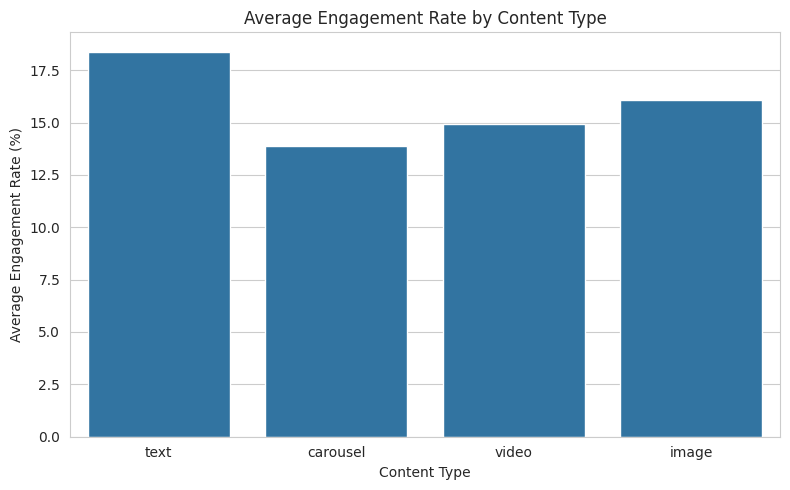

In [34]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x='content_type',
    y='calculated_engagement_rate',
    estimator='mean',
    errorbar=None
)

plt.title('Average Engagement Rate by Content Type')
plt.xlabel('Content Type')
plt.ylabel('Average Engagement Rate (%)')
plt.tight_layout()
plt.show()

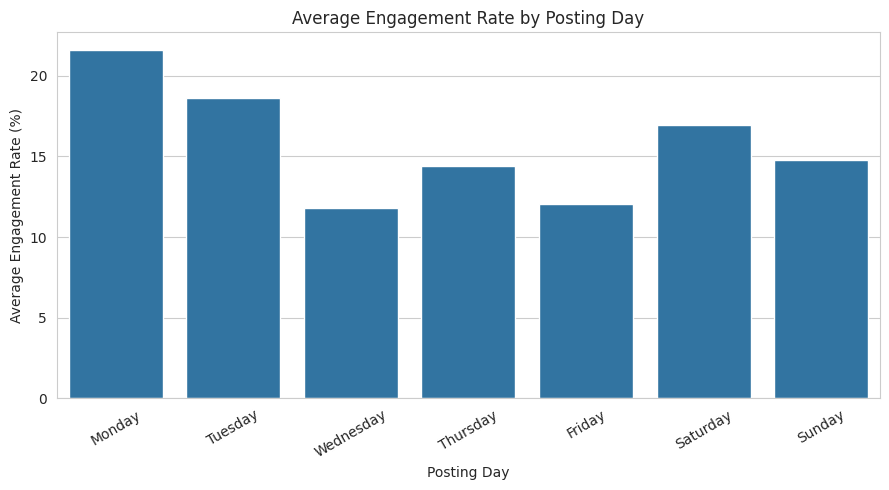

In [35]:
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

df_clean['posting_day'] = (
    df_clean['post_datetime'].dt.day_name()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_clean,
    x='posting_day',
    y='calculated_engagement_rate',
    order=day_order,
    estimator='mean',
    errorbar=None
)

plt.title('Average Engagement Rate by Posting Day')
plt.xlabel('Posting Day')
plt.ylabel('Average Engagement Rate (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

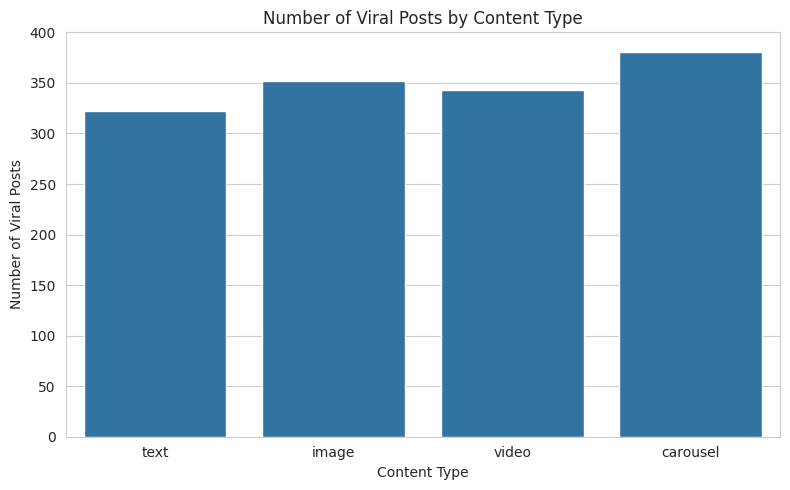

In [36]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean[df_clean['is_viral'] == 1],
    x='content_type',
    order=['text', 'image', 'video', 'carousel']
)

plt.title('Number of Viral Posts by Content Type')
plt.xlabel('Content Type')
plt.ylabel('Number of Viral Posts')
plt.tight_layout()
plt.show()

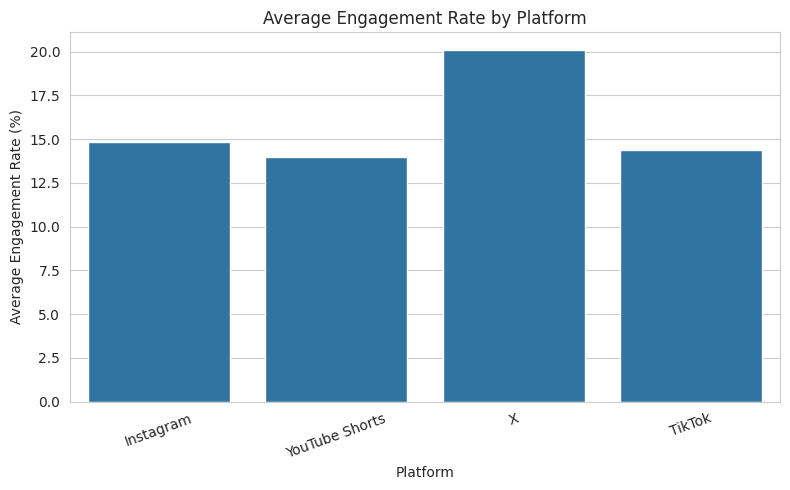

In [37]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x='platform',
    y='calculated_engagement_rate',
    estimator='mean',
    errorbar=None
)

plt.title('Average Engagement Rate by Platform')
plt.xlabel('Platform')
plt.ylabel('Average Engagement Rate (%)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [38]:
df_clean['posting_day'] = (
    df_clean['post_datetime'].dt.day_name()
)

df_clean['total_engagement'] = (
    df_clean['likes'] +
    df_clean['comments'] +
    df_clean['shares']
)

df_clean['calculated_engagement_rate'] = (
    df_clean['total_engagement'] /
    df_clean['views']
) * 100

df_clean['high_engagement_flag'] = (
    df_clean['calculated_engagement_rate'] > 100
)

df_clean['interaction_exceeds_views'] = (
    df_clean['total_engagement'] > df_clean['views']
)

df_clean['view_outlier'] = (
    (df_clean['views'] < lower_limit) |
    (df_clean['views'] > upper_limit)
)

print("Final dataset shape:", df_clean.shape)
display(df_clean.head())

Final dataset shape: (2000, 24)


,post_id,platform,content_type,topic,language,region,post_datetime,hashtags,views,likes,...,is_viral,total_engagement,calculated_engagement_rate,dataset_rate_percent,rate_difference,interaction_exceeds_views,view_outlier,posting_day,posting_hour,high_engagement_flag
0,SM_100000,Instagram,text,Sports,ur,UK,2024-12-10,#tech #funny #music,2319102,122058,...,1,138719,5.981583,5.98,0.001583,False,False,Tuesday,0,False
1,SM_100001,Instagram,carousel,Sports,ur,Brazil,2024-10-13,#news #fyp #funny #ai #trending,2538464,110368,...,1,176544,6.954757,6.95,0.004757,False,False,Sunday,0,False
2,SM_100002,YouTube Shorts,video,Technology,ur,UK,2024-05-03,#ai #news,1051176,87598,...,0,178926,17.021507,17.02,0.001507,False,False,Friday,0,False
3,SM_100003,X,text,Politics,ur,US,2024-08-04,#ai #funny,5271440,329465,...,1,389975,7.397884,7.40,0.002116,False,False,Sunday,0,False
4,SM_100004,YouTube Shorts,text,Education,es,US,2024-03-28,#news #ai #viral #funny #fyp,3186256,199141,...,1,287562,9.025075,9.03,0.004925,False,False,Thursday,0,False


In [40]:
df_clean.to_csv(
    'social_media_cleaned.csv',
    index=False
)

from google.colab import files
files.download('social_media_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:
from google.colab import files
uploaded = files.upload()

Saving social_media_cleaned.csv to social_media_cleaned (1).csv


In [46]:
import pandas as pd

df_sql = pd.read_csv('social_media_cleaned.csv')

print("Total records:", len(df_sql))
print("Columns:", df_sql.columns.tolist())

Total records: 2000
Columns: ['post_id', 'platform', 'content_type', 'topic', 'language', 'region', 'post_datetime', 'hashtags', 'views', 'likes', 'comments', 'shares', 'engagement_rate', 'sentiment_score', 'is_viral', 'total_engagement', 'calculated_engagement_rate', 'dataset_rate_percent', 'rate_difference', 'interaction_exceeds_views', 'view_outlier', 'posting_day', 'posting_hour', 'high_engagement_flag']


In [47]:

import pandas as pd
from google.colab import files

df_sql = pd.read_csv('social_media_cleaned.csv')

columns = [
    'post_id', 'platform', 'content_type', 'topic', 'language',
    'region', 'post_datetime', 'hashtags', 'views', 'likes',
    'comments', 'shares', 'engagement_rate', 'sentiment_score',
    'is_viral', 'total_engagement', 'calculated_engagement_rate',
    'posting_day', 'high_engagement_flag',
    'interaction_exceeds_views', 'view_outlier'
]

def sql_value(value, column):
    if pd.isna(value):
        return "NULL"

    if column == 'post_datetime':
        date = pd.to_datetime(value).strftime('%Y-%m-%d')
        return f"TO_DATE('{date}', 'YYYY-MM-DD')"

    if column in [
        'is_viral', 'high_engagement_flag',
        'interaction_exceeds_views', 'view_outlier'
    ]:
        return str(int(value))

    if column in [
        'views', 'likes', 'comments', 'shares',
        'engagement_rate', 'sentiment_score',
        'total_engagement', 'calculated_engagement_rate'
    ]:
        return str(value)

    value = str(value).replace("'", "''")
    return f"'{value}'"

sql_statements = []

for start in range(0, len(df_sql), 100):
    batch = df_sql.iloc[start:start + 100]

    statement = ["INSERT ALL"]

    for _, row in batch.iterrows():
        values = [
            sql_value(row[col], col) for col in columns
        ]

        statement.append(
            f"INTO social_media_posts ({', '.join(columns)}) "
            f"VALUES ({', '.join(values)})"
        )

    statement.append("SELECT 1 FROM dual;")
    sql_statements.append("\n".join(statement))

sql_script = "\n\n".join(sql_statements)

with open("social_media_insert.sql", "w", encoding="utf-8") as file:
    file.write(sql_script)

print("SQL file generated successfully!")
print("Total records:", len(df_sql))
print("Total SQL batches:", len(sql_statements))

files.download("social_media_insert.sql")


SQL file generated successfully!
Total records: 2000
Total SQL batches: 20


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
from google.colab import files

df.to_csv('social_media_original.csv', index=False)

files.download('social_media_original.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>